<a href="https://colab.research.google.com/github/simichakravarty16/walmart-hurricane-project/blob/main/notebooks/2026-10-23%20%E2%80%94%20Midterm%20Checkpoint%20%E2%80%94%20Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DS2002 · Midterm Checkpoint

**Lab — 2026-10-23 · Fall 2026**  

---

## Lab 09 — Midterm checkpoint, week 1 of 3

**What you submit: the link to your team's main repo. Only that.** One submission per team. Do not upload separate files.

Put this notebook in the repo (the `notebooks/` folder is fine) and push it, so everything we check is in one place.

**You do not have to fill this all out.** It is a checkpoint, not a finished project. Skip any section you have not started and write "not started" next to it. What we must see is:

1. **Your charter**, committed to the repo
2. **Any progress** you have made, with code that ran and output you can point at

Start with the team setup, then work down the same eight things we listed at Monday's kickoff, as far as you have gotten. This is graded on evidence, not on intentions.

The purpose is to catch a stalled team while there is still time to unstall it. If something is not working, say so here plainly. A checkpoint that honestly reports "the API join is not working and here is the error" is worth more than one that claims progress that does not exist, and it gets you help on Monday.

### Team setup

This part is required. Fill it in once for the whole team.

You need:

- Your team name, and every member with a GitHub handle (2 to 4 people)
- A link to your team's **main repo**. This is the one link you submit.
- A link to `CHARTER.md` in that repo, the page on GitHub, not a file on someone's laptop

Nice to have, and also in your charter: this week's notebook owner, your meeting time, and the five worst problems in the data from the profile you ran on Monday. Be specific: "`unit_price` is stored as text and some values start with `$`" beats "prices are messy."

In [1]:
team_setup = {
    'team_name': 'Walmart Warriors',
    'members': [                                  # everyone on the team, 2 to 4 people
        {'name': 'Simi Chakravarty', 'github': 'simichakravarty16'},
        {'name': 'Xiangyu Shi', 'github': 'ShiX27'},
    ],
    'repo_url': 'https://github.com/simichakravarty16/walmart-hurricane-project.git',                           # your main team repo: https://github.com/...
    'charter_url': 'https://github.com/simichakravarty16/walmart-hurricane-project/blob/1ac90f563ca6c428bb9f4421c704c06671779cc0/CHARTER.md',                        # link to CHARTER.md in that repo
    'notebook_owner_this_week': 'Xiangyu',           # nice to have
    'meeting_time': '9AM on Wednesdays',                       # nice to have, e.g. 'Tue and Thu 7pm'
    'five_worst_problems': [
        'There are 886 nulls in the timestamp column.',
        'The unit_price column is stored as text and some values start with $.',
        'The sku and product_name columns have different numbers of distinct values.',
        'The store_id column contains more distinct values than the 12 unique store IDs in the store_locations.csv (after removing duplicates) due to inconsistent spelling and formating.',
        'There are 30 duplicate rows.'
        ],              # nice to have, five specific problems
}

def check_team(t, quiet=False):
    def real(v):
        return isinstance(v, str) and v.strip() != '' and not v.startswith('TODO')
    required = {
        'team name': real(t['team_name']),
        '2 to 4 members, each with a name and GitHub handle':
            2 <= len(t['members']) <= 4 and all(real(m['name']) and real(m['github']) for m in t['members']),
        'main repo link': real(t['repo_url']) and t['repo_url'].startswith('https://github.com/'),
        'charter link points at CHARTER.md': real(t['charter_url']) and t['charter_url'].endswith('CHARTER.md'),
    }
    nice = {
        'notebook owner': real(t['notebook_owner_this_week']),
        'meeting time': real(t['meeting_time']),
        'five specific problems': len(t['five_worst_problems']) >= 5 and all(real(p) for p in t['five_worst_problems']),
    }
    if not quiet:
        print('REQUIRED')
        for label, good in required.items():
            print('  PASS' if good else '  FAIL', '-', label)
        print('NICE TO HAVE')
        for label, good in nice.items():
            print('  done' if good else '  not yet', '-', label)
        print()
        print('team setup complete:', all(required.values()))
    return all(required.values())

check_team(team_setup)

REQUIRED
  PASS - team name
  PASS - 2 to 4 members, each with a name and GitHub handle
  PASS - main repo link
  PASS - charter link points at CHARTER.md
NICE TO HAVE
  done - notebook owner
  done - meeting time
  done - five specific problems

team setup complete: True


True

Now show that the charter is actually committed. This is required. Run the next cell and leave its output in the notebook. Point `REPO_PATH` at your local clone of the team repo. If it prints a line like `a1b2c3d Add team charter`, you are done. If it prints "no commits found," the charter is not in the repo yet, so commit it and push before you submit.

In [2]:
!git clone https://github.com/simichakravarty16/walmart-hurricane-project.git

fatal: destination path 'walmart-hurricane-project' already exists and is not an empty directory.


In [3]:
import subprocess

REPO_PATH = '/content/walmart-hurricane-project'      # your local clone of the team repo

result = subprocess.run(['git', '-C', REPO_PATH, 'log', '--oneline', '--', 'CHARTER.md'],
                        capture_output=True, text=True)
print(result.stdout.strip() or 'no commits found for CHARTER.md')

99efb79 Add files via upload
3c27b9b Delete CHARTER.md
d711dbd Upload CHARTER.md
aec52c3 Delete CHARTER.md
10a221e Create CHARTER.md


### 1 — Your cleaning pipeline as functions

**TODO:** paste the cleaning code you have written so far. It should be functions, not loose cells, and it should cover at minimum: duplicates, `unit_price` to numeric (it comes in as text, some with a `$`), the negative `quantity` values with your decision applied, `timestamp` parsed, and `store_id` cleaned up so it will join to the store file.

Print the row count before and after. We want to see how many rows your decisions removed.

In [4]:
import pandas as pd
import os
import sqlite3
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests, time

In [5]:
DECISIONS = []

def log(dataset, step, decision, rows_affected):
    DECISIONS.append({'dataset': dataset, 'step': step, 'decision': decision, 'rows': rows_affected})
    print(f'[{dataset}] [{step}] {decision} ({rows_affected} row(s))')

In [6]:
# Set data directory
DATA_DIR = '/content'

# Define data loading function
def load_data(filename):
  return pd.read_csv(os.path.join(DATA_DIR, filename))

In [7]:
# Load walmart transactions dataset
transactions = load_data('walmart_transactions.csv')
transactions.head()

,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price
0,TXN012636,FL-710,2024-09-24T09:48:13,PNUTBTR-16,PEANUT BUTTER,Grocery,1,3.15
1,TXN000759,fl-412,2024-09-13 20:30:20,CNSOUP-01,CANNED SOUP,GROCERY,1,2.02
2,TXN003338,FL-105,2024-09-17 10:06:00,TOILETPAPER12,Toilet Paper 12-Roll,Household Essentials,2,10.47
3,TXN025020,FL-330,2024-09-11 06:29:08,ROKU-STD,Roku Streaming Stick,ELECTRONICS,1,28.59
4,TXN015797,FL-302,2024-09-26 15:59:42,BEER-24,Light Beer 24pk,Alcoholic Beverages,3,18.82


Problems:
1. There are 30 duplicate rows in the dataset.
2. There are 886 nulls in the `timestamp` column. Missing values are represented in several ways, including empty strings, `NULL`, `N/A`, `NaN`, and `nan`.
3. Dates and times are in different formats in the `timestamp` column.
4. The same products appear under different SKUs and product names.
5. There are inconsistencies in capitalization and spacing.
6. The same products have different category names.
7. The `unit_price` column is stored as `str` instead of `float`, and some values  contains `$` signs.
8. There are negative quantities in the `quantity` column.  
9. The `store_id` column does not consistently follow the `FL-#` format.

In [8]:
# Transform: Types and Duplicates
def transform_types(df):
    out = df.copy()

    # Drop duplicates
    before = len(out)
    out = out.drop_duplicates()
    removed = before - len(out)
    log('walmart_transactions', 'remove duplicates', 'Removed duplicate rows', removed)

    # Normalize timestamps
    out['timestamp'] = pd.to_datetime(out['timestamp'], errors='coerce', format='mixed')
    missing = out['timestamp'].isna().sum()
    log('walmart_transactions', 'clean timestamp', 'Converted timestamps to datetime and kept missing values as NaT', missing)

    # Create date column for joining with daily weather data
    out['date'] = out['timestamp'].dt.normalize()
    log('walmart_transactions', 'create date column', 'Extracted calendar date from timestamp for weather merge', out['date'].notna().sum())

    # Convert unit_price to float (no $ sign)
    out['unit_price'] = (out['unit_price'].astype(str)
                         .str.replace('$', '', regex=False) # remove $ sign
                         .str.strip().astype(float))    # change unit prices to float
    affected_price = len(out)
    log('walmart_transactions', 'clean unit_price', 'Removed $ sign and converted unit_price to float', affected_price)

    # Clean quantity
    before = len(out)
    out['quantity'] = pd.to_numeric(out['quantity'], errors='coerce')
    # Decision: drop the unparseable quantity and the return. We are measuring
    # units that left the shelf ahead of the hurricane, so a return is not that.
    out = out[out['quantity'].notna() & (out['quantity'] > 0)].copy()
    out['quantity'] = out['quantity'].astype(int)
    removed_quantity = before - len(out)
    log('walmart_transactions', 'clean quantity', 'Removed negative quantities (returns)', removed_quantity)

    # Standardize store_id
    old_id = out['store_id'].copy()
    out['store_id'] = out['store_id'].astype(str).str.upper().str.strip().str.replace(r'^FL[\s_-]*(\d+)$', r'FL-\1', regex=True)
    affected_id = (old_id != out['store_id']).sum()
    log('walmart_transactions', 'clean store_id', 'Standardized store IDs to FL-# format', affected_id)

    return out

In [9]:
# Transform: consolidate SKUs, product names, and categories

# Consolidate SKUs
SKU_MAP = {
    'BATT_AA_4PK': 'BAT-AA4',
    'BATT-100': 'BAT-AA4',
    'BEER-24': 'LTBEER24',
    'BABYFORMULA': 'BFORM-01',
    'BG-MONO': 'BG-MONO-01',
    'MONOPOLY-01': 'BG-MONO-01',
    'GAME-MONO': 'BG-MONO-01',
    'BREAD-WH': 'WHITEBREAD',
    'CNDL-EM': 'CANDLE-EMRG',
    'PLAYCARD-STD': 'CARDS-01',
    'CHIPVARIETY': 'CHIPS-VP',
    'PORTCHARGER': 'CHRG-PORT',
    'SOUP-CAN': 'CNSOUP-01',
    'DIAPERS-3': 'DIAP-S3',
    'FIRSTAID-KIT': 'FAID-01',
    'LED-FLASH': 'FLASH-01',
    'TARP-HD': 'HDTARP-01',
    'PAPERTOWEL6': 'PTOWEL6',
    'PTOWEL-6': 'PTOWEL6',
    'TOILETPAPER12': 'TOILETPAPER-12',
    'TP-12': 'TOILETPAPER-12',
    'PB-16': 'PNUTBTR-16',
    'PT-12': 'POPTART-STRAW',
    'SKU#459812': 'POPTART-STRAW',
    'PT_STRAWBERRY': 'POPTART-STRAW',
    'ROKU-STD': 'ROKU-STREAM',
    'STREAM-01': 'ROKU-STREAM',
    'WATER24PK': 'WATER-24',
    'WTR_24PK': 'WATER-24',
    'WTR-24': 'WATER-24'
}

# Standardize product names
PRODUCT_MAP = {
    'BAT-AA4': 'Batteries AA 4PK',
    'LTBEER24': 'Light Beer 24PK',
    'BFORM-01': 'Baby Formula',
    'BG-MONO-01': 'Monopoly Board Game',
    'WHITEBREAD': 'White Bread',
    'CANDLE-EMRG': 'Emergency Candle',
    'CARDS-01': 'Playing Cards',
    'CHIPS-VP': 'Chip Variety Pack',
    'CHRG-PORT': 'Portable Phone Charger',
    'CNSOUP-01': 'Canned Soup',
    'DIAP-S3': 'Diapers Size 3',
    'FAID-01': 'First Aid Kit',
    'FLASH-01': 'LED Flashlight',
    'HDTARP-01': 'Heavy Duty Tarp',
    'PTOWEL6': 'Paper Towels 6PK',
    'TOILETPAPER-12': 'Toilet Paper 12PK',
    'PNUTBTR-16': 'Peanut Butter 16oz',
    'POPTART-STRAW': 'Pop-Tarts Strawberry',
    'ROKU-STREAM': 'Roku Streaming Stick',
    'WATER-24': 'Bottled Water 24PK'
}

# Standardize categories
CATEGORY_MAP = {
    'Alcoholic Beverages': 'Alcohol',
    'Baby Products': 'Baby',
    'Breakfast Foods': 'Breakfast',
    'Emergency Supplies': 'Emergency',
    'Groceries': 'Grocery',
    'Games & Entertainment': 'Entertainment',
    'Health & Wellness': 'Health',
    'Household Essentials': 'Household'
}

def consolidate_transactions(df):
    out = df.copy()

    # Consolidate SKUs
    old_sku = out['sku'].copy()
    out['sku'] = out['sku'].map(SKU_MAP).fillna(out['sku'])
    affected_sku = (old_sku != out['sku']).sum()
    log('walmart_transactions', 'clean sku', 'Consolidated SKUs so the same products share the same SKU', affected_sku)

    # Standardize product names
    old_name = out['product_name'].copy()
    out['product_name'] = out['sku'].map(PRODUCT_MAP).fillna(out['product_name'])
    affected_name = (old_name != out['product_name']).sum()
    log('walmart_transactions', 'clean product_name', 'Standardized product names based on SKUs for consistency', affected_name)

    # Standardize categories
    old_category = out['category'].copy()
    out['category'] = out['category'].str.strip().str.title().replace(CATEGORY_MAP)
    affected_category = (old_category != out['category']).sum()
    log('walmart_transactions', 'clean category', 'Standardized category names, capitalization, and spacing', affected_category)

    return out

Decisions:
1. We removed the 30 duplicate rows to avoid counting the same transactions more than once during analysis.
2. We converted `timestamp` column to datetime to ensure a consistent format. We used `format='mixed'` to handle different timestamp formats and `errors='coerce'` to convert missing or invalid timestamps to `NaT` instead of raising errors. We decided to keep rows with missing timestamps because they contain other useful transaction information. These rows will be excluded later from analyses that require transaction dates.
3. We created the `date` column for joining with daily weather data.
4. We removed the `$` sign from the `unit_price` column and converted the values from strings to floats so that we can use numerical values to calculate revenue later if needed.
5. We decided to remove rows with negative quantities because our analysis focuses on units sold ahead of the hurricane, and returns do not represent units leaving store shelves.
6. We standardized the `store_id`column to the `FL-#` format to ensure consistency and allow accurate merging with the `clean_stores` dataset.
7. We consolidated different SKUs representing the same products into one canonical SKU to ensure consistency and avoid treating them as different products during analysis.
8. We standardized `product_name` based on SKUs to ensure that the same products have consistent names and avoid treating them as different products during analysis.
9. We standardized the `category` column to ensure consistent category names and capitalization and avoid incorrect grouping during analysis.

In [10]:
def clean_walmart_transactions(df):
    df = transform_types(df)
    df = consolidate_transactions(df)
    return df

clean_transactions = clean_walmart_transactions(transactions)
display(clean_transactions.head())

print('Shape:', clean_transactions.shape)
print('\nData Types:')
print(clean_transactions.dtypes)
print()

# Check number of rows before and after cleaning
print('Rows before cleaning:', len(transactions))
print('Rows after cleaning:', len(clean_transactions))
print('Rows removed:', len(transactions) - len(clean_transactions))

[walmart_transactions] [remove duplicates] Removed duplicate rows (30 row(s))
[walmart_transactions] [clean timestamp] Converted timestamps to datetime and kept missing values as NaT (884 row(s))
[walmart_transactions] [create date column] Extracted calendar date from timestamp for weather merge (24648 row(s))
[walmart_transactions] [clean unit_price] Removed $ sign and converted unit_price to float (25532 row(s))
[walmart_transactions] [clean quantity] Removed negative quantities (returns) (130 row(s))
[walmart_transactions] [clean store_id] Standardized store IDs to FL-# format (4324 row(s))
[walmart_transactions] [clean sku] Consolidated SKUs so the same products share the same SKU (16702 row(s))
[walmart_transactions] [clean product_name] Standardized product names based on SKUs for consistency (20155 row(s))
[walmart_transactions] [clean category] Standardized category names, capitalization, and spacing (18649 row(s))


,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price,date
0,TXN012636,FL-710,2024-09-24 09:48:13,PNUTBTR-16,Peanut Butter 16oz,Grocery,1,3.15,2024-09-24
1,TXN000759,FL-412,2024-09-13 20:30:20,CNSOUP-01,Canned Soup,Grocery,1,2.02,2024-09-13
2,TXN003338,FL-105,2024-09-17 10:06:00,TOILETPAPER-12,Toilet Paper 12PK,Household,2,10.47,2024-09-17
3,TXN025020,FL-330,2024-09-11 06:29:08,ROKU-STREAM,Roku Streaming Stick,Electronics,1,28.59,2024-09-11
4,TXN015797,FL-302,2024-09-26 15:59:42,LTBEER24,Light Beer 24PK,Alcohol,3,18.82,2024-09-26


Shape: (25402, 9)

Data Types:
transaction_id            object
store_id                  object
timestamp         datetime64[ns]
sku                       object
product_name              object
category                  object
quantity                   int64
unit_price               float64
date              datetime64[ns]
dtype: object

Rows before cleaning: 25562
Rows after cleaning: 25402
Rows removed: 160


The number of rows before cleaning was 25,562, and the number of rows after cleaning was 25,402. In total, we removed 160 rows during the cleaning process.

**Code Explanation:** First, we created a function named `clean_walmart_transactions()` to call the `transform_types()` and `consolidate_transactions()` functions defined above for data cleaning. We then passed the `transactions` DataFrame to the `clean_walmart_transactions()` function and stored the result in `clean_transactions`. Next, we displayed the first five rows of the `clean_transactions` DataFrame. Second, we displayed the number of rows and columns in `clean_transactions` and the data type of each column. Finally, we displayed the number of rows before and after cleaning and the total number of rows removed.

### 2 — Your decision log

**TODO:** every cleaning decision, what it did, and how many rows it touched. If your teammates disagree with one of these, note the disagreement — that is useful information, not a problem to hide.

In [11]:
# TODO: print or display your decision log
pd.DataFrame(DECISIONS)

,dataset,step,decision,rows
0,walmart_transactions,remove duplicates,Removed duplicate rows,30
1,walmart_transactions,clean timestamp,Converted timestamps to datetime and kept miss...,884
2,walmart_transactions,create date column,Extracted calendar date from timestamp for wea...,24648
3,walmart_transactions,clean unit_price,Removed $ sign and converted unit_price to float,25532
4,walmart_transactions,clean quantity,Removed negative quantities (returns),130
5,walmart_transactions,clean store_id,Standardized store IDs to FL-# format,4324
6,walmart_transactions,clean sku,Consolidated SKUs so the same products share t...,16702
7,walmart_transactions,clean product_name,Standardized product names based on SKUs for c...,20155
8,walmart_transactions,clean category,"Standardized category names, capitalization, a...",18649


### 3 — SKU consolidation progress

**TODO:** how many distinct SKUs did you start with, how many canonical products do you have now, and what is your largest consolidated group? Show the mapping for at least one product family. Pop-Tarts is a good one to start with.

You do not need this finished — you need it started and defensible.

In [12]:
# Compare before and after cleaning
print('original distinct SKUs:', transactions['sku'].nunique())
print('original distinct product names:', transactions['product_name'].nunique())
print('canonical SKUs:', clean_transactions['sku'].nunique())
print('canonical products:', clean_transactions['product_name'].nunique())

# Map original SKUs to canonical SKUs
sku_mapping = transactions[['sku']].drop_duplicates().copy()
sku_mapping['canonical_sku'] = sku_mapping['sku'].map(SKU_MAP).fillna(sku_mapping['sku'])

# Count original SKUs per canonical SKU
sku_counts = sku_mapping.groupby('canonical_sku')['sku'].nunique().sort_values(ascending=False)
print('\nSKUs per canonical SKU:')
print(sku_counts)

# Strawberry Pop-Tarts SKU mapping
poptart_mapping = sku_mapping[sku_mapping['canonical_sku'] == 'POPTART-STRAW']
print('\nStrawberry Pop-Tarts SKU mapping:')
display(poptart_mapping)


original distinct SKUs: 45
original distinct product names: 63
canonical SKUs: 20
canonical products: 20

SKUs per canonical SKU:
canonical_sku
POPTART-STRAW     4
BAT-AA4           3
WATER-24          3
BG-MONO-01        3
CANDLE-EMRG       2
BFORM-01          2
CARDS-01          2
CHIPS-VP          2
DIAP-S3           2
FAID-01           2
CHRG-PORT         2
CNSOUP-01         2
HDTARP-01         2
FLASH-01          2
PNUTBTR-16        2
LTBEER24          2
PTOWEL6           2
ROKU-STREAM       2
TOILETPAPER-12    2
WHITEBREAD        2
Name: sku, dtype: int64

Strawberry Pop-Tarts SKU mapping:


,sku,canonical_sku
21,PT_STRAWBERRY,POPTART-STRAW
27,SKU#459812,POPTART-STRAW
47,PT-12,POPTART-STRAW
52,POPTART-STRAW,POPTART-STRAW


Before cleaning, the dataset contained 45 distinct SKUs and 63 distinct product names. After consolidation, we reduced them to 20 canonical SKUs and 20 standardized product names. The largest consolidated group was Strawberry Pop-Tarts, with four original SKUs (PT_STRAWBERRY, SKU#459812, PT-12, and POPTART-STRAW) mapped to one canonical SKU (POPTART-STRAW). This ensures that sales of Strawberry Pop-Tarts are analyzed together rather than treated as separate products.

**Code Explanation:** First, we used `.nunique()` to count the number of distinct SKUs and product names before and after cleaning. Second, we created the `sku_mapping` DataFrame by selecting the `sku` column from the original transactions and removing duplicate SKUs. We then used `SKU_MAP` to map the original SKUs to their canonical SKUs, keeping the original SKU if no mapping was found. Third, we grouped `sku_mapping` by `canonical_sku`, counted the number of original SKUs mapped to each canonical SKU, sorted the values in descending order, and stored the results in `sku_counts`. Finally, we filtered `sku_mapping` to display the four original Strawberry Pop-Tarts SKUs mapped to the canonical SKU `POPTART-STRAW`.

### 4 — One working weather API call

**TODO:** show the call and the parsed DataFrame. It must include the retry logic and a `source` column. Say which timezone the weather timestamps are in and how you will line them up with the sales timestamps. If it is not working, paste the actual error and what you have tried.

In [13]:
BASE = 'https://archive-api.open-meteo.com/v1/archive'
RETRY_STATUSES = {429, 500, 502, 503, 504}

def daily_weather(start, end, lat=28.54, lon=-81.38, tries=3):
    params = {
        'latitude': lat, 'longitude': lon,
        'start_date': start, 'end_date': end,
        'daily': 'precipitation_sum,windspeed_10m_max,pressure_msl_mean',
        'timezone': 'America/New_York', # the sales timestamps are based on time in florida, which corresponds to America/New_York timezone
    }
    for attempt in range(1, tries + 1):
        try:
            r = requests.get(BASE, params=params, timeout=10)
        except (requests.Timeout, requests.ConnectionError):
            if attempt == tries:
                raise
            time.sleep(2 ** attempt)
            continue
        if r.status_code in RETRY_STATUSES:
            if attempt == tries:
                r.raise_for_status()
            time.sleep(2 ** attempt)
            continue
        r.raise_for_status()
        frame = pd.DataFrame(r.json()['daily'])
        frame = frame.rename(columns={'time': 'date'})
        frame['date'] = pd.to_datetime(frame['date'])
        frame['source'] = 'open-meteo'
        return frame

FALLBACK = pd.DataFrame({
    'date': pd.date_range('2024-09-01', periods=30),
    'precipitation_sum': [3.0, 12.4, 24.9, 22.1, 23.1, 9.3, 6.8, 94.7, 28.0, 14.4,
                          12.0, 0.7, 0.6, 21.1, 1.2, 7.9, 2.3, 13.3, 1.4, 0.7,
                          0.4, 2.2, 1.3, 0.3, 6.4, 15.2, 2.5, 18.0, 4.6, 3.3],
    'windspeed_10m_max': [18.8, 13.5, 22.8, 15.5, 15.2, 9.0, 14.2, 12.6, 11.5, 14.3,
                          15.8, 12.1, 10.4, 17.4, 9.0, 13.3, 12.4, 9.3, 12.9, 15.3,
                          19.9, 17.9, 16.6, 17.7, 27.2, 48.8, 45.1, 19.8, 11.7, 8.6],
    'pressure_msl_mean': [1015.2, 1014.8, 1013.9, 1014.5, 1015.1, 1016.0, 1015.7, 1014.2, 1013.8, 1014.6,
                          1015.4, 1016.1, 1015.8, 1014.9, 1015.6, 1016.3, 1015.9, 1014.7, 1015.2, 1014.4,
                          1013.6, 1012.8, 1011.9, 1010.5, 1008.7, 1006.2, 1009.4, 1012.1, 1014.0, 1015.3],
    'source': 'fallback sample',
})

try:
    weather_live = daily_weather('2024-09-01', '2024-09-30')
except requests.RequestException as err:
    print('API call failed:', err)
    weather_live = FALLBACK

weather = weather_live.copy()

merged = clean_transactions.merge(weather, on='date', how='left', indicator=True)

assert len(merged) == len(clean_transactions), 'the join changed the row count'
assert not (merged['_merge'] == 'right_only').any(), 'weather rows with no sales day'   # a left join can't make these; this guards against someone changing how= later
assert merged['quantity'].sum() == clean_transactions['quantity'].sum(), 'the orders total changed'

print(f'{merged['_merge'].value_counts()}\n')

print("Sales rows:", len(clean_transactions))
print("Merged rows:", len(merged))
print("Sales rows with no weather match:",
      (merged['_merge'] == 'left_only').sum())

merged.head()

_merge
both          24521
left_only       881
right_only        0
Name: count, dtype: int64

Sales rows: 25402
Merged rows: 25402
Sales rows with no weather match: 881


,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price,date,precipitation_sum,windspeed_10m_max,pressure_msl_mean,source,_merge
0,TXN012636,FL-710,2024-09-24 09:48:13,PNUTBTR-16,Peanut Butter 16oz,Grocery,1,3.15,2024-09-24,0.3,17.7,1013.5,open-meteo,both
1,TXN000759,FL-412,2024-09-13 20:30:20,CNSOUP-01,Canned Soup,Grocery,1,2.02,2024-09-13,0.9,10.4,1012.7,open-meteo,both
2,TXN003338,FL-105,2024-09-17 10:06:00,TOILETPAPER-12,Toilet Paper 12PK,Household,2,10.47,2024-09-17,2.5,12.4,1013.7,open-meteo,both
3,TXN025020,FL-330,2024-09-11 06:29:08,ROKU-STREAM,Roku Streaming Stick,Electronics,1,28.59,2024-09-11,12.0,15.8,1012.4,open-meteo,both
4,TXN015797,FL-302,2024-09-26 15:59:42,LTBEER24,Light Beer 24PK,Alcohol,3,18.82,2024-09-26,14.4,48.8,1004.5,open-meteo,both


**Code Explanation:** I first defined BASE as the URL for Open-Mateo's API so that I could store it for future use. RETRY_STATUSES is a list of HTTP status codes that I want my function to retry the API call on in case it does not work. Next, I defined the daily_weather() function, which requests weather data a defined amount of times from Open-Mateo for a given date range and location. The specific daily_weather parameters were the start date, end date, latitude (defined for Orlando as main location of hurricane), longitude (defined for Orlando as main location of hurricane), and tries (max number of attempts to request the data). The request parameters (weather data requested from Open-Mateo) are latitude, longitude, start_date, end_date, daily (dataframe containing precipitation, wind speed, and barometric pressure), and setting timezome as America/New_York to account for sale timestamps based on Florida local time. Setting the API timezone to America/New_York ensures that weather data's daily dates are defined using the same time as the transaction data. The for loop in the daily_weather() function makes up to 3 attempts, with each having a 10 second timeout so it won't wait too long to receive a response. The first error handler is to check if there are connection problems/timeouts. If it was the last attempt, a error raises, and if it is not, then the code waits before trying again in an exponentially increasing delay. The next part is for errors in RETRY_STATUSES, which raises an error for unseccessful HTTP responses so the user can fix the issue instead of repeatedly requesting the data. If the request succeeds, the API's JSON response is parsed into a dataframe. The time column is renamedd to date, so that it can be more easily joined to the transaction data. pd.to_datetime converts date strings into standard pandas datetime values. This code also creates a source column to record if the data came from the Open-Mateo API and then returns the dataframe. I also defined a FALLBACK dataframe, so that the notebook will still run even if the weather API does not work, but still prints an error. The source column helps to distinguish between whether the data came from Open-Mateo or the FALLBACK dataframe. Next, I left joined the weather dataframe to the transactions data and used assertions to make sure that the row count stayed the same, there were no weather rows with no sales days, and that the orders total did not change. I then displayed these results to show the number of rows in each merge category, the original and merged row counts, and the number of sales rows without a matched weather date.

### 5 — One chart

**TODO:** daily order volume across your date range. It does not need to be presentation quality yet, but it does need labeled axes and a title.

Look at it before you submit. Does the shape make sense? An early chart is the fastest way to catch a cleaning bug — if your daily volume has a day at zero or a day at ten times everything else, that is usually your pipeline, not the hurricane.

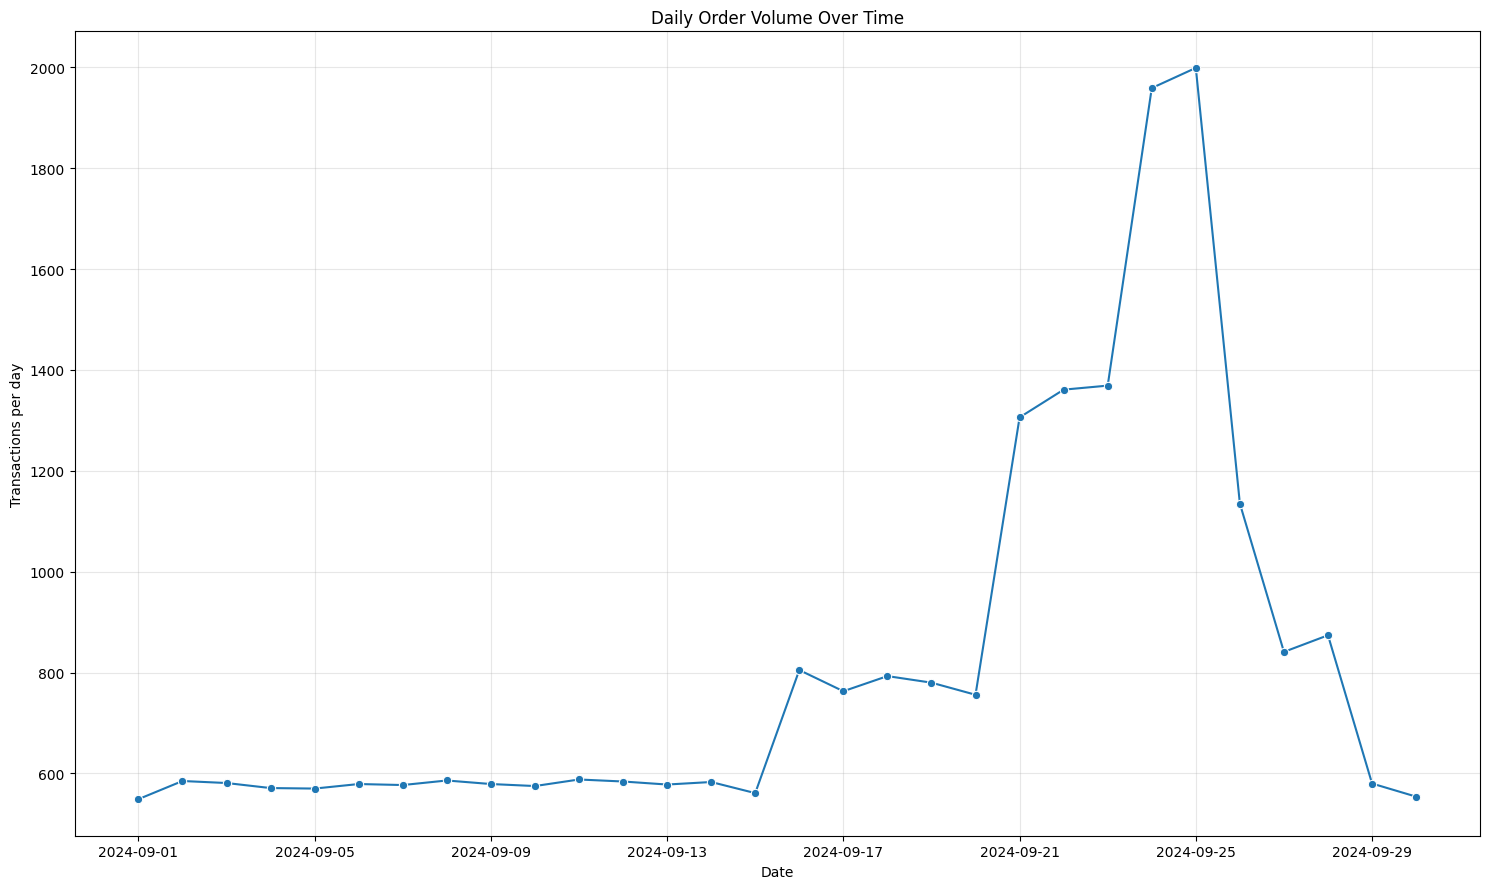

In [14]:
daily_orders = (clean_transactions.dropna(subset=['timestamp'])
                    .groupby(clean_transactions['timestamp'].dt.date)
                    .size()
                    .reset_index(name='order_count')
)

# Create line chart
fig, ax = plt.subplots(figsize=(15, 9))
sns.lineplot(data=daily_orders, x='timestamp', y='order_count', marker='o', ax=ax)

ax.set_title('Daily Order Volume Over Time')
ax.set_xlabel('Date')
ax.set_ylabel('Transactions per day')
ax.set_xticks(daily_orders['timestamp'][::4])

ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

The shape makes sense. The chart shows a recognizable pattern, with relatively stable daily transactions from September 1-15, a moderate increase from September 15-20, and a sharp increase from September 20-25, reaching approximately 2,000 transactions on September 25. This was followed by a sharp decline toward earlier transaction levels from September 25-30. There are no days with zero transactions or unusually extreme spikes that clearly indicate data cleaning errors.

### 6 — Self-check

Fill in what you have and leave the rest. **The required items are the team setup and the charter.** Everything else is progress we want to see, not a pass or fail. The checks are shape checks; they cannot verify your analysis is right, only that you have gotten far enough to have one.

In [15]:
required = {
    'team_setup_complete': check_team(team_setup, quiet=True),   # from the team setup section
    'charter_committed': True,         # TODO: True once CHARTER.md shows in the git log above
}

progress = {
    'rows_after_cleaning': 25402,        # an integer
    'decisions_logged': 9,               # how many entries in your log
    'canonical_products': 20,         # distinct products after consolidation
    'weather_api_rows': len(merged),           # rows returned by your API call
    'notebook_runs_clean': True,       # True after Restart and Run All
}

def is_done(value):
    return not (value is None or value is False
                or (isinstance(value, str) and value.startswith('TODO')))

def check(required, progress):
    print('REQUIRED')
    for label, value in required.items():
        print('  PASS' if is_done(value) else '  FAIL', '-', label, '=', value)
    print('PROGRESS (fill in what you have)')
    for label, value in progress.items():
        print('  done' if is_done(value) else '  not yet', '-', label, '=', value)
    ok = all(is_done(v) for v in required.values())
    print()
    print('required items complete:', ok)
    print('progress items done:', sum(is_done(v) for v in progress.values()), 'of', len(progress))
    return ok

check(required, progress)

REQUIRED
  PASS - team_setup_complete = True
  PASS - charter_committed = True
PROGRESS (fill in what you have)
  done - rows_after_cleaning = 25402
  done - decisions_logged = 9
  done - canonical_products = 20
  done - weather_api_rows = 25402
  done - notebook_runs_clean = True

required items complete: True
progress items done: 5 of 5


True

### 7 — Risk and plan

Two questions, answered concretely.

**a)** What is the single most likely thing to go wrong in the next two weeks? Name a specific technical or team problem, not "running out of time."

**b)** What are you doing about it this week? Name who is doing it and by when.

**Biggest risk:** Inconsistent store IDs, product SKUs, or dates across datasets could cause errors when merging the data.

**Plan, with an owner and a date:**
*   Xiangyu was responsible for cleaning and standardizing all four CSV datasets by October 23 and started working on analytical questions 1 and 2 by October 25.
*   Simi was responsible for calling the weather API, merging the datasets, and started working on analytical questions 3 and 4 by October 25.



### 8 — Where each question stands

**TODO:** mark each of the five questions. These owners must match the question owners table in your charter. Be honest — this is the section I read first.

| Question | Status | Who owns it |
|---|---|---|
| Q1 demand surge |in progress | Xiangyu |
| Q2 SKU consolidation |in progress| Xiangyu |
| Q3 weather correlation | in progress | Simi |
| Q4 store and geography | in progress | Simi |
| Q5 signal or artifact | not started | Simi and Xiangyu |

At the end of week 1, "not started" on Q4 and Q5 is expected. "Not started" on all five means come find me on Monday.